In [6]:
import re

def extraer_dosis(archivo, region_objetivo=700):
    with open(archivo, "r", encoding="utf-8") as f:
        contenido = f.read()

    patron = (
        rf"^\s*\d+\s+{region_objetivo}\s+"
        rf"[\d.Ee+-]+\s+([\d.Ee+-]+)\s+[\d.Ee+-]+"
    )

    coincidencia = re.search(patron, contenido, re.MULTILINE)

    if coincidencia:
        return float(coincidencia.group(1))

    raise ValueError(
        f"No se encontró la dosis para la región {region_objetivo}"
    )


archivo = r"..\out\dosis.out"

dosis = extraer_dosis(archivo)

print(f"Dosis en región 5: {dosis} Gy/source")

Dosis en región 5: 0.073489 Gy/source


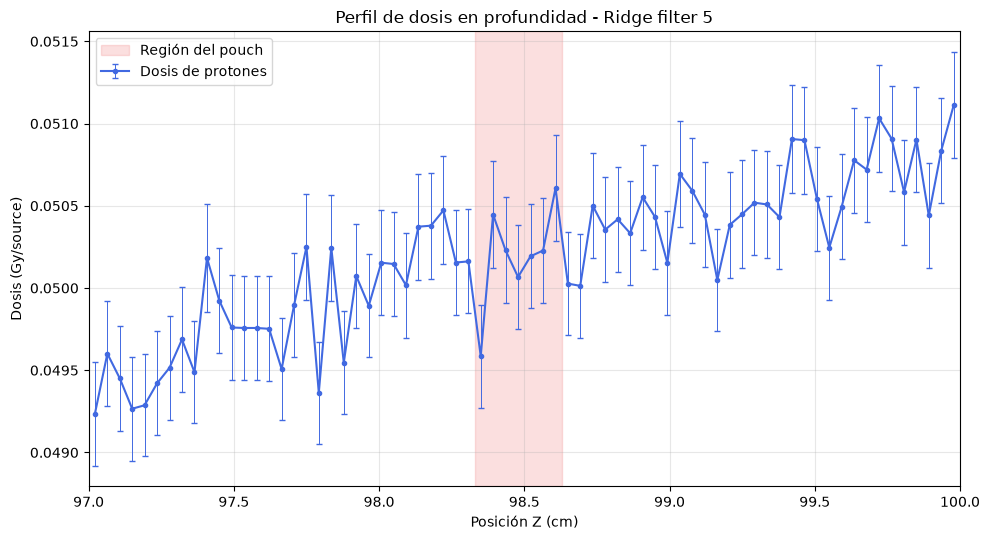

In [3]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

archivo = Path("../out/bragg_pouch.out")

datos = []
leyendo = False

for linea in archivo.read_text().splitlines():
    if linea.strip().startswith("#  z-lower"):
        leyendo = True
        continue

    if leyendo:
        if linea.strip().startswith("#   sum"):
            break

        valores = linea.split()

        if len(valores) == 4:
            try:
                datos.append([float(v) for v in valores])
            except ValueError:
                continue

datos = np.array(datos)

z = (datos[:, 0] + datos[:, 1]) / 2
dosis = datos[:, 2]
error = dosis * datos[:, 3]

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.errorbar(
    z, dosis, yerr=error,
    fmt="o-", color="royalblue",
    markersize=3, linewidth=1.5,
    capsize=2, elinewidth=0.7,
    label="Dosis de protones"
)

ax.axvspan(
    98.33, 98.63,
    color="lightcoral", alpha=0.25,
    label="Región del pouch"
)

ax.set(
    title="Perfil de dosis en profundidad - Ridge filter 5",
    xlabel="Posición Z (cm)",
    ylabel="Dosis (Gy/source)"
)

ax.set_xlim(97, 100)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()
